Hi, welcome to the data processing notebook.

This one is tailored to the Camalan Mining-Pond Change Data Set (our labeled ground-truth one).

it takes the image data and the binary mask data present in each of the 16 folders given in that data set.

use the function load_region(<insert region_id here>) to retrieve the arrays for any region

I've included many notes explaining each code bloc to preserve clarity. 

- Julius

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from PIL import Image
from pathlib import Path
import pandas as pd

#depending on your current data/folder organization/naming, 
#you may need to change some things in this cell
project_dir = Path.cwd()
region_root = project_dir / "downloaded data" / "Bigger_Set_21_19_HistMatch"

#prints the directory
print("Project directory:", project_dir)
print("Data directory exists:", region_root.exists())

#if the data folder isn't found, raise an error msg.
if not region_root.is_dir():
    raise FileNotFoundError(
        f"Missing Camalan dataset folder: {region_root}\n"
    
    )

region_dirs = sorted(
    (p for p in region_root.iterdir() if p.is_dir() and p.name.isdigit()),
    key=lambda p: int(p.name)
)
print(f"Found {len(region_dirs)} region folders: {[p.name for p in region_dirs]}")

Project directory: c:\Users\rbima\OneDrive\Desktop\UT_Hub\UT Fall 2026\Intro to GeoAI\FinalProject
Data directory exists: True
Found 16 region folders: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16']


Ok, now we're going to do a few things to start:
1. verify array sizes for each region in the directory
2. 

In [2]:
#initialize a variable that holds all the data we call
records = []

#for each folder, do a few things:
#1. ensure there are two images and masks
#2. capture info on each component such as pixel #, shape, etc.
#3. assemble all that into one master table that we export as .csv
for region_dir in region_dirs:
    image_files = sorted(region_dir.glob("*_ch6.mat"))
    mask_files = sorted(region_dir.glob("*Binary_change_thr.png"))

    #if there is an unexpected # of images or masks, raise an error
    if len(image_files) != 2 or len(mask_files) != 1:
            raise ValueError(
                f"Region {region_dir.name}: expected 2 ch6 images and 1 binary mask, "
                f"found {len(image_files)} and {len(mask_files)}."
            )

    #initialize 3 variables, we now actually load them 
    first = loadmat(image_files[0])["new"]
    second = loadmat(image_files[1])["new"]
    mask = np.asarray(Image.open(mask_files[0]))

    # ensure all our data lines up / is the same shape / etc.
    if first.shape != second.shape or first.shape[:2] != mask.shape:
            raise ValueError(f"Region {region_dir.name}: image/mask dimensions disagree")
    if first.ndim != 3 or first.shape[2] != 6:
            raise ValueError(f"Region {region_dir.name}: unexpected channel count {first.shape}")
    if not set(np.unique(mask)).issubset({0, 255}):
            raise ValueError(f"Region {region_dir.name}: non-binary mask values")

#this variable becomes useful in the append you see below
    positive = (mask > 0)

    #we now add our images and masks to the records variable
    #in doing so, we save information like height, width, channels, etc.
    #we leave split unassigned as we don't know the train/test split yet
    records.append({
           "region_id":int(region_dir.name),
           "height": int(first.shape[0]),
           "width": int(first.shape[1]),
           "channels_per_date": int(first.shape[2]),
            "positive_pixels": int(positive.sum()),
            "positive_pct": round(float(positive.mean()) * 100, 2),
            "image_1": image_files[0].relative_to(project_dir).as_posix(),
            "image_2": image_files[1].relative_to(project_dir).as_posix(),
            "mask": mask_files[0].relative_to(project_dir).as_posix(),
            "split": "unassigned",
    })

#we declare a dataframe with our records, sorted by region_id
manifest = pd.DataFrame(records).sort_values("region_id").reset_index(drop=True)
#save that to a table
manifest.to_csv(project_dir / "camalan_data.csv", index=False)

print(f"Verified {len(manifest)} image pairs and masks.")
print("Table save succesful!")
display(manifest[["region_id", "height", "width", "positive_pct", "split"]])

Verified 16 image pairs and masks.
Table save succesful!


,region_id,height,width,positive_pct,split
0,1,667,654,8.21,unassigned
1,2,667,655,8.97,unassigned
2,3,556,546,10.46,unassigned
3,4,888,482,14.57,unassigned
4,5,667,655,8.45,unassigned
5,6,1109,548,13.74,unassigned
6,7,556,546,9.41,unassigned
7,8,556,545,14.06,unassigned
8,9,555,438,17.50,unassigned
9,10,556,545,14.38,unassigned


In [3]:
#define a loader function, this should be reusable
#it will return the two things:
#1. X - (height, width, 12) from images (6 channels)
#2. y - (height, width) of the binary change masks where (0 = unchanged, 1= change)

#depending on your model of choice:
#you will need to reshape X to fit your purposes

def load_region(region_id: int, metadata: pd.DataFrame = manifest):
    #ensure region given when calling function is valid
    matches = metadata.loc[metadata["region_id"] == region_id]
    if len(matches) != 1:
           raise KeyError(f"Region {region_id} not found in your table!")
    #if success, call row and save it to variable "row"
    row = matches.iloc[0]

    #from the row extract the images
    first = loadmat(project_dir / row["image_1"])["new"]
    second = loadmat(project_dir / row["image_2"])["new"]
    mask = np.asarray(Image.open(project_dir / row["mask"]))

    #validate again that all shapes match
    if first.shape != second.shape or first.shape[:2] != mask.shape:
          raise ValueError(f"REgion {region_id} image and mask sizes differ")

    X = np.concatenate((first,second), axis=-1).astype(np.float32) / 255.0
    y = (mask > 0).astype(np.uint8)

    return X, y


    


    



In [4]:
#NOTE: this is a test cell to ensure the function is calling correctly
X1, y1 = load_region(1)
print("X:", X1.shape, X1.dtype, "range", (float(X1.min()), float(X1.max())))
print("y:", y1.shape, y1.dtype, "values", np.unique(y1))
print("Positive change pixels:", int(y1.sum()))

assert X1.shape == (667, 654, 12)
assert y1.shape == (667, 654)

X: (667, 654, 12) float32 range (0.01568627543747425, 1.0)
y: (667, 654) uint8 values [0 1]
Positive change pixels: 35809


Ok, now we have our arrays, but they aren't georeferenced. The purpose of this next part is to:

1. turn coordinate data that we only have in table form in an academic paper abstract into a useable form that we can use to georeference our images
2. match the correct coordinates to the correct region_id, otherwise our georeferencing is useless

In [5]:
# Dimensions reported in Camalan et al., Appendix A, Table A1
# Problem: our current region_id's may not align correctly
# with the data. 

#so in this cell, we take the shape of the data described in the paper 
# and match them to our data

published_shapes = {
    1: (667, 654),
    2: (667, 655),
    3: (556, 546),
    4: (556, 545),
    5: (1109, 548),
    6: (667, 655),
    7: (888, 482),
    8: (556, 545),
    9: (556, 546),
    10: (555, 438),
    11: (1109, 657),
    12: (1333, 659),
    13: (894, 1309),
    14: (1337, 1311),
    15: (1560, 1748),
    16: (668, 655)
}

# for each row in our .csv file, match height and widths
# then print possible matches for each one
for _, row in manifest.iterrows():
    region_id = int(row["region_id"])
    actual = (int(row["height"]), int(row["width"]))

    matches = [
        published_id
        for published_id, shape in published_shapes.items()
        if shape == actual
    ]

    print(
        f"Downloaded Region {region_id:>2}: "
        f"{actual} -> Possible published regions: {matches}"
    )

Downloaded Region  1: (667, 654) -> Possible published regions: [1]
Downloaded Region  2: (667, 655) -> Possible published regions: [2, 6]
Downloaded Region  3: (556, 546) -> Possible published regions: [3, 9]
Downloaded Region  4: (888, 482) -> Possible published regions: [7]
Downloaded Region  5: (667, 655) -> Possible published regions: [2, 6]
Downloaded Region  6: (1109, 548) -> Possible published regions: [5]
Downloaded Region  7: (556, 546) -> Possible published regions: [3, 9]
Downloaded Region  8: (556, 545) -> Possible published regions: [4, 8]
Downloaded Region  9: (555, 438) -> Possible published regions: [10]
Downloaded Region 10: (556, 545) -> Possible published regions: [4, 8]
Downloaded Region 11: (1109, 657) -> Possible published regions: [11]
Downloaded Region 12: (1333, 659) -> Possible published regions: [12]
Downloaded Region 13: (894, 1309) -> Possible published regions: [13]
Downloaded Region 14: (1337, 1311) -> Possible published regions: [14]
Downloaded Region 1

ok, so we have mismatching regions, but since we can't verify for sure which is which easily right now, we will just save these as "candidate" matches

In [6]:
# Create a table linking downloaded regions to possible
# geographic regions described in Camalan et al., Table A1.

#new variable
candidate_records = []

#for each row in the OG table:
for _, row in manifest.iterrows():

    region_id = int(row["region_id"])
    actual_shape = (int(row["height"]), int(row["width"]))

    #match region_id to possible matches
    candidates = [
        paper_id
        for paper_id, shape in published_shapes.items()
        if shape == actual_shape
    ]


    candidate_records.append({
        "region_id": region_id,
        "possible_paper_regions": str(candidates),
        "unique_match": len(candidates) == 1
    })

#create a crosswalk table, denoting the region_id, possible matches
#from the paper, and whether a region has one match or not

region_crosswalk = pd.DataFrame(candidate_records)

display(region_crosswalk)

region_crosswalk.to_csv(
    project_dir / "region id crosswalk.csv",
    index=False
)

,region_id,possible_paper_regions,unique_match
0,1,[1],True
1,2,"[2, 6]",False
2,3,"[3, 9]",False
3,4,[7],True
4,5,"[2, 6]",False
5,6,[5],True
6,7,"[3, 9]",False
7,8,"[4, 8]",False
8,9,[10],True
9,10,"[4, 8]",False


In [7]:
import geopandas as gpd
from shapely.geometry import box

# Camalan et al., Appendix A, Table A1
# Coordinate order: (west, south, east, north)
# CRS: WGS84 latitude/longitude, EPSG:4326

#we use the published coordinate boundaries 
# (which i have converted to WKT)

published_bounds = {
    1: (-69.9248611, -13.0310833, -69.8648611, -12.9710833),
    2: (-69.9770278, -13.0227222, -69.9170278, -12.9627222),
    3: (-70.0150000, -13.0075833, -69.9650000, -12.9575833),
    4: (-70.0554444, -13.0121111, -70.0054444, -12.9621111),
    5: (-70.0433333, -12.9951111, -69.9933333, -12.8951111),
    6: (-70.1132778, -12.9895556, -70.0532778, -12.9295556),
    7: (-70.0825000, -12.9545278, -70.0385000, -12.8745278),
    8: (-70.0599444, -12.8921389, -70.0099444, -12.8421389),
    9: (-70.0207500, -12.9262778, -69.9707500, -12.8762778),
    10: (-69.9964444, -12.8886944, -69.9564444, -12.8386944),
    11: (-69.9644722, -12.8633889, -69.9044722, -12.7633889),
    12: (-70.5168889, -13.0962222, -70.4568889, -12.9762222),
    13: (-70.6592222, -13.0372778, -70.5392222, -12.9572778),
    14: (-70.6361389, -12.9468056, -70.5161389, -12.8268056),
    15: (-70.5958056, -12.8318889, -70.4358056, -12.6918889),
    16: (-70.2701944, -12.9653333, -70.2101944, -12.9053333)
}

# NOTE: Published Region 3 appears to contain an N/S typo;
# i assumed it was south, not north. because that would not be peru

#we initialize a geodataframe with these coordinates
#in that geodataframe we make a polygon out of each coordinate set
published_gdf = gpd.GeoDataFrame(
    {
        "paper_region": list(published_bounds.keys())
    },
    geometry=[
        box(*bounds)
        for bounds in published_bounds.values()
    ],
    crs="EPSG:4326"
)

display(published_gdf.head())

,paper_region,geometry
0,1,"POLYGON ((-69.86486 -13.03108, -69.86486 -12.9..."
1,2,"POLYGON ((-69.91703 -13.02272, -69.91703 -12.9..."
2,3,"POLYGON ((-69.965 -13.00758, -69.965 -12.95758..."
3,4,"POLYGON ((-70.00544 -13.01211, -70.00544 -12.9..."
4,5,"POLYGON ((-69.99333 -12.99511, -69.99333 -12.8..."


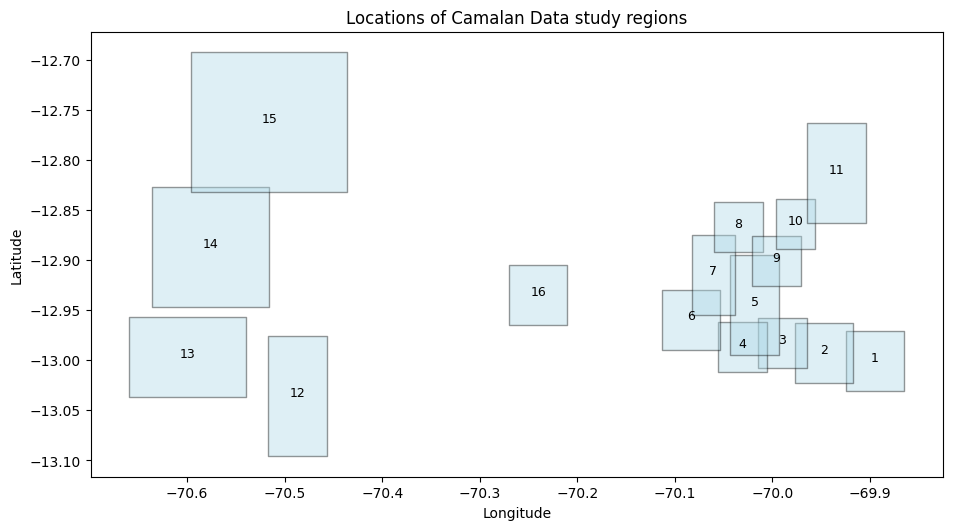

In [8]:
#now that we have 16 polygons to match up with our data (mostly)
#we now plot them

fig, ax = plt.subplots(figsize=(11, 9))

published_gdf.plot(
    ax=ax,
    facecolor="lightblue",
    edgecolor="black",
    alpha=0.4
)

for _, row in published_gdf.iterrows():
    center = row.geometry.centroid

    ax.annotate(
        str(row["paper_region"]),
        (center.x, center.y),
        ha="center",
        fontsize=9
    )

ax.set_title("Locations of Camalan Data study regions")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.show()

#saved as a GeoJSON, which can be opened in ArcPRO or QGIS
published_gdf.to_file(
    project_dir / "camalan_published_regions.geojson",
    driver="GeoJSON"
)

In [9]:

# Downloaded folder ID -> published paper region ID
region_mapping = {
    1: 1,
    2: 2,
    3: 3,
    4: 7,
    5: 6,
    6: 5,
    7: 9,
    8: 4,
    9: 10,
    10: 8,
    11: 11,
    12: 12,
    13: 13,
    14: 14,
    15: 15,
    16: 16
}

assert set(region_mapping.keys()) == set(range(1, 17))
assert set(region_mapping.values()) == set(range(1, 17))

for _, row in manifest.iterrows():

    folder_id = int(row["region_id"])
    actual_shape = (int(row["height"]), int(row["width"]))

    matches = [
        paper_id
        for paper_id, shape in published_shapes.items()
        if shape == actual_shape
    ]

    if len(matches) == 1:
        region_mapping[folder_id] = matches[0]

print("Unique dimension matches:")
for folder_id, paper_id in region_mapping.items():
    print(f"Downloaded {folder_id} -> Published {paper_id}")

print("Total:", len(region_mapping))

Unique dimension matches:
Downloaded 1 -> Published 1
Downloaded 2 -> Published 2
Downloaded 3 -> Published 3
Downloaded 4 -> Published 7
Downloaded 5 -> Published 6
Downloaded 6 -> Published 5
Downloaded 7 -> Published 9
Downloaded 8 -> Published 4
Downloaded 9 -> Published 10
Downloaded 10 -> Published 8
Downloaded 11 -> Published 11
Downloaded 12 -> Published 12
Downloaded 13 -> Published 13
Downloaded 14 -> Published 14
Downloaded 15 -> Published 15
Downloaded 16 -> Published 16
Total: 16


In [10]:
import rasterio
from rasterio.transform import from_bounds

# Create a folder for georeferenced masks
output_dir = project_dir / "georeferenced_masks"
output_dir.mkdir(exist_ok=True)

for folder_id, paper_id in region_mapping.items():

    # Load satellite imagery and reference mask
    X, y = load_region(folder_id)

    # Retrieve published geographic coordinates
    west, south, east, north = published_bounds[paper_id]

    # Construct pixel-to-coordinate transformation
    transform = from_bounds(
        west, south, east, north,
        width=y.shape[1],
        height=y.shape[0]
    )

    # Save as a georeferenced GeoTIFF
    output_path = output_dir / f"region_{folder_id}_change_mask.tif"

    with rasterio.open(
        output_path,
        "w",
        driver="GTiff",
        height=y.shape[0],
        width=y.shape[1],
        count=1,
        dtype=y.dtype,
        crs="EPSG:4326",
        transform=transform,
        compress="lzw"
    ) as dst:
        dst.write(y, 1)

    print(f"Saved downloaded region {folder_id} "
          f"(published {paper_id})")

print("\nFinished exporting candidate masks!")

Saved downloaded region 1 (published 1)
Saved downloaded region 2 (published 2)
Saved downloaded region 3 (published 3)
Saved downloaded region 4 (published 7)
Saved downloaded region 5 (published 6)
Saved downloaded region 6 (published 5)
Saved downloaded region 7 (published 9)
Saved downloaded region 8 (published 4)
Saved downloaded region 9 (published 10)
Saved downloaded region 10 (published 8)
Saved downloaded region 11 (published 11)
Saved downloaded region 12 (published 12)
Saved downloaded region 13 (published 13)
Saved downloaded region 14 (published 14)
Saved downloaded region 15 (published 15)
Saved downloaded region 16 (published 16)

Finished exporting candidate masks!


In [11]:
# just updating manifest with all our georeferenced regions
manifest["paper_region"] = manifest["region_id"].map(region_mapping)

# Add geographic coordinates
for column, index in [
    ("west", 0),
    ("south", 1),
    ("east", 2),
    ("north", 3)
]:
    manifest[column] = manifest["paper_region"].apply(
        lambda region: published_bounds[region][index]
    )

# Add paths to the georeferenced masks
manifest["georeferenced_mask"] = manifest["region_id"].apply(
    lambda region: f"georeferenced_masks/region_{region}_change_mask.tif"
)

# Save the updated manifest
manifest.to_csv(
    project_dir / "camalan_manifest.csv",
    index=False
)

display(manifest[[
    "region_id", "paper_region",
    "west", "south", "east", "north",
    "georeferenced_mask"
]])

,region_id,paper_region,west,south,east,north,georeferenced_mask
0,1,1,-69.924861,-13.031083,-69.864861,-12.971083,georeferenced_masks/region_1_change_mask.tif
1,2,2,-69.977028,-13.022722,-69.917028,-12.962722,georeferenced_masks/region_2_change_mask.tif
2,3,3,-70.015000,-13.007583,-69.965000,-12.957583,georeferenced_masks/region_3_change_mask.tif
3,4,7,-70.082500,-12.954528,-70.038500,-12.874528,georeferenced_masks/region_4_change_mask.tif
4,5,6,-70.113278,-12.989556,-70.053278,-12.929556,georeferenced_masks/region_5_change_mask.tif
5,6,5,-70.043333,-12.995111,-69.993333,-12.895111,georeferenced_masks/region_6_change_mask.tif
6,7,9,-70.020750,-12.926278,-69.970750,-12.876278,georeferenced_masks/region_7_change_mask.tif
7,8,4,-70.055444,-13.012111,-70.005444,-12.962111,georeferenced_masks/region_8_change_mask.tif
8,9,10,-69.996444,-12.888694,-69.956444,-12.838694,georeferenced_masks/region_9_change_mask.tif
9,10,8,-70.059944,-12.892139,-70.009944,-12.842139,georeferenced_masks/region_10_change_mask.tif


whew, take a breather if you've made it this far in. 

ok. so now we've extracted all our data, georeferenced it, and have it ready to go.

you might ask, what's next?

the fun part. assigning test and train splits....

fuck.

so usually you would kind of just pick randomly, but consider this:

our data, when viewed from a map, kind of naturally forms 3 clusters:

11 in one big eastern cluster - a good training set?,
4 in a western cluster - a good testing set?
and 1 centrally located polygon - a good validation set

how our authors allowed this and made that work for ML... I don't know, but that's what we're working with.

To those who would say that we risk overfitting for the training area and we won't be able to generalize our results: I say, fuck you. let me cook.

In [12]:
# so now we assign our splits

#first 11 (eastern cluster) are for training
#the lone central polygon (16) for validation
#the other 4, test
def assign_split(paper_region):
    if paper_region in range(1, 12):
        return "train"
    elif paper_region == 16:
        return "validation"
    else:
        return "test"

manifest["split"] = manifest["paper_region"].apply(assign_split)

# Examine the assignments
display(
    manifest[[
        "region_id",
        "paper_region",
        "positive_pct",
        "split"
    ]]
)

print("\nSplit counts:")
print(manifest["split"].value_counts())

,region_id,paper_region,positive_pct,split
0,1,1,8.21,train
1,2,2,8.97,train
2,3,3,10.46,train
3,4,7,14.57,train
4,5,6,8.45,train
5,6,5,13.74,train
6,7,9,9.41,train
7,8,4,14.06,train
8,9,10,17.50,train
9,10,8,14.38,train



Split counts:
split
train         11
test           4
validation     1
Name: count, dtype: int64


In [13]:
#because we don't want overlaps in training/testing areas,
#this step validates that we don't

from shapely.geometry import box
from itertools import combinations

# Create a geographic footprint for each downloaded region
manifest["geometry"] = manifest.apply(
    lambda row: box(
        row["west"],
        row["south"],
        row["east"],
        row["north"]
    ),
    axis=1
)

# Check for overlapping footprints across different splits
overlaps = []

for (_, a), (_, b) in combinations(manifest.iterrows(), 2):

    if a["split"] != b["split"]:
        if a["geometry"].intersects(b["geometry"]):
            overlaps.append((
                a["region_id"],
                b["region_id"]
            ))

print("Overlaps between different splits:", overlaps)
#if you got "[]" as an answer, we good.

Overlaps between different splits: []


In [14]:
# Save the final manifest, including geographic splits
manifest.drop(
    columns=["geometry"],
    errors="ignore"
).to_csv(
    project_dir / "camalan_manifest.csv",
    index=False
)

print("Saved final manifest with train/validation/test splits.")

Saved final manifest with train/validation/test splits.


# Step 4(ish)
Ok. Let's take inventory:
we now have our manifest table. we've assigned splits for training and testing. we have georeferenced masks that we can load in gis easily. 

What we don't have is ML ready data though; this is our next objective. 

NOTE: If you've found yourself confused by the next cell, read the following:

**I'm going to break our images, which are all different sizes into uniform 128x128 pixel patches.**

According to ChatGPT and this guy on medium (https://medium.com/artefact-engineering-and-data-science/leveraging-satellite-imagery-for-machine-learning-computer-vision-applications-d22143f72d94), this makes the data uniform, more manageable, and makes our small dataset signficantly larger, which should somewhat help our models. 

However, since U-net and Random Forest don't really digest data in the same way, we still need to reformat the patch for each model.

here goes.

In [21]:
#let's make a patch function! 
#comprised, as all fun functions are, of many smalelr functions!


def patch_starts(length, patch_size=128, stride=128):
    starts = list(range(0, length - patch_size + 1, stride))

    #this ensures our final patch reaches the image boundary
    if starts[-1] != length - patch_size:
        starts.append(length - patch_size)

    return starts

#this loads one patch for a region at a time
def iter_region_patches(region_id, patch_size=128, stride=128):

    #select your region
    X, y = load_region(region_id)

    #initialize # of rows and columns (pixels) in patch
    rows = patch_starts(X.shape[0], patch_size, stride)
    cols = patch_starts(X.shape[1], patch_size, stride)

    #for each patch position:
    for row in rows:
        for col in cols:

            #select those in X that are in the patch
            X_patch = X[
                row:row + patch_size,
                col:col + patch_size,
            ]
            #select y that are in the patch
            y_patch = y[
                row:row + patch_size,
                col:col + patch_size,
            ]

            #unlike return, ield gives us the patches one at a time
            #upon request. this avoids computing them all at once.
            yield X_patch, y_patch, (row, col)

#this one loads all patches for a region
def load_region_patches(region_id, patch_size=128):
    patches = list(
        iter_region_patches(region_id, patch_size=patch_size)
    )

    X_patches = np.stack([p[0] for p in patches])
    y_patches = np.stack([p[1] for p in patches])

    return X_patches, y_patches

def combine_split_patches(split_name):
    #find regions in the split
    region_ids = manifest.loc[
        manifest["split"] == split_name,
        "region_id"
    ]

    X_list = []
    y_list = []
    id_list = []

    for region_id in region_ids:
        #load every patch from each region in the split
        X, y = load_region_patches(int(region_id))

        X_list.append(X)
        y_list.append(y)

        #ensure we keep track of region for each patch
        id_list.append(
            np.full(len(X), region_id, dtype=np.uint8)
        )

        print(f"Region {region_id}: {len(X)} patches")


    #now we combine the lists into arrays
    X_all = np.concatenate(X_list, axis=0)
    y_all = np.concatenate(y_list, axis=0)
    region_ids_all = np.concatenate(id_list)

    return X_all, y_all, region_ids_all


In [19]:
#we now test the function
# Retrieve the first patch from Region 1
patch_generator = iter_region_patches(1)

X_patch, y_patch, position = next(patch_generator)

print("X patch:", X_patch.shape)
print("y patch:", y_patch.shape)
print("Pixel position:", position)
print("Change pixels:", y_patch.sum())

X patch: (128, 128, 12)
y patch: (128, 128)
Pixel position: (0, 0)
Change pixels: 101


In [20]:
X_patches, y_patches = load_region_patches(1)

print("Image patches:", X_patches.shape)
print("Mask patches:", y_patches.shape)

print(
    "Memory used:",
    round((X_patches.nbytes + y_patches.nbytes) / 1024**2, 2),
    "MiB"
)

assert X_patches.shape == (36, 128, 128, 12)
assert y_patches.shape == (36, 128, 128)

Image patches: (36, 128, 128, 12)
Mask patches: (36, 128, 128)
Memory used: 27.56 MiB


In [22]:
#now that we have our datasets, we make a folder and save them

model_dir = project_dir / "model_data"
model_dir.mkdir(exist_ok=True)

for split_name in ["train", "validation"]:

    X, y, region_ids = combine_split_patches(split_name)

    # Save everything into one file per split
    output_path = model_dir / f"{split_name}_patches.npz"

    np.savez_compressed(
        output_path,
        X=X,
        y=y,
        region_ids=region_ids
    )

    print(f"\n{split_name.upper()} DATASET")
    print("X:", X.shape)
    print("y:", y.shape)
    print("Regions:", np.unique(region_ids))
    print("Saved to:", output_path, "\n")

Region 1: 36 patches
Region 2: 36 patches
Region 3: 25 patches
Region 4: 28 patches
Region 5: 36 patches
Region 6: 45 patches
Region 7: 25 patches
Region 8: 25 patches
Region 9: 20 patches
Region 10: 25 patches
Region 11: 54 patches

TRAIN DATASET
X: (355, 128, 128, 12)
y: (355, 128, 128)
Regions: [ 1  2  3  4  5  6  7  8  9 10 11]
Saved to: c:\Users\rbima\OneDrive\Desktop\UT_Hub\UT Fall 2026\Intro to GeoAI\FinalProject\model_data\train_patches.npz 

Region 16: 36 patches

VALIDATION DATASET
X: (36, 128, 128, 12)
y: (36, 128, 128)
Regions: [16]
Saved to: c:\Users\rbima\OneDrive\Desktop\UT_Hub\UT Fall 2026\Intro to GeoAI\FinalProject\model_data\validation_patches.npz 

